# 🍎 Fruits — классификация изображений с MobileNetV2

Короткий эксперимент на 269 классах [Fruits-360](https://www.kaggle.com/datasets/moltean/fruits).
Исходный кейс: [Kaggle](https://www.kaggle.com/code/mrmoderator/fruits).

Три эпохи на фиксированной быстрой подвыборке; validation отделена от test.
Ноутбук содержит фактический вывод запуска на TensorFlow 2.19.0.
Подробные метрики и ограничения оценки приведены в README.

## 1. Библиотеки и параметры

In [7]:
import json
import os
from pathlib import Path

import numpy as np
import pandas as pd
import textwrap
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image

SEED = 42
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32
EPOCHS = 3
FAST_MODE = True
FAST_TRAIN_PER_CLASS = 24
FAST_VAL_PER_CLASS = 8
FAST_TEST_PER_CLASS = 16
VALIDATION_SPLIT = 0.2
tf.keras.utils.set_random_seed(SEED)
ARTIFACT_DIR = Path('artifacts')
ARTIFACT_DIR.mkdir(exist_ok=True)

## 2. Пути к данным
Локально положите Training и Test в data/fruits-360/ или задайте FRUITS_DATA_DIR. В Kaggle стандартный путь определяется автоматически. Для первой загрузки ImageNet-весов нужен интернет; офлайн можно задать путь MOBILENET_WEIGHTS.

In [8]:
candidates = [
    Path('/kaggle/input/datasets/moltean/fruits/fruits-360_100x100/fruits-360'),
    Path('/kaggle/input/fruits/fruits-360_100x100/fruits-360'),
    Path('data/fruits-360'),
]
configured = os.environ.get('FRUITS_DATA_DIR')
DATA_ROOT = Path(configured) if configured else next(
    (path for path in candidates if (path / 'Training').is_dir()), candidates[-1]
)
train_dir = DATA_ROOT / 'Training'
test_dir = DATA_ROOT / 'Test'
if not train_dir.is_dir() or not test_dir.is_dir():
    raise FileNotFoundError('Нужны Training/ и Test/. Укажите FRUITS_DATA_DIR.')
kaggle_weights = Path('/kaggle/input/datasets/mrmoderator/mobilenet-v2/mobilenet_v2_weights_tf_dim_ordering_tf_kernels_1.0_224_no_top.h5')
weights_source = os.environ.get('MOBILENET_WEIGHTS') or (
    str(kaggle_weights) if kaggle_weights.is_file() else 'imagenet'
)
print('Dataset:', DATA_ROOT)

Dataset: /kaggle/input/datasets/moltean/fruits/fruits-360_100x100/fruits-360


## 3. Быстрый эксперимент с отдельными train / validation / test
По умолчанию выбраны 24 train-, 8 validation- и 16 test-изображений каждого класса.
Validation берётся из Training, test — из отдельной папки Test. Подвыборки фиксированы seed=42.
Аугментации используются только для train. FAST_MODE=False включает полный набор с 20% validation.
preprocess_input приводит пиксели к [-1, 1].

In [9]:
rng = np.random.default_rng(SEED)
class_names = sorted(path.name for path in train_dir.iterdir() if path.is_dir())
test_paths = [path for path in test_dir.iterdir() if path.is_dir()]
test_directories = {path.name.casefold(): path for path in test_paths}
if len(test_directories) != len(test_paths) or len({name.casefold() for name in class_names}) != len(class_names):
    raise ValueError('Неоднозначные названия классов без учёта регистра')
missing_test = [name for name in class_names if name.casefold() not in test_directories]
if missing_test:
    raise ValueError(f'В Test нет классов: {missing_test}')

def list_images(directory):
    # Listing names avoids a remote stat call for every image in Kaggle.
    return sorted(directory / name for name in os.listdir(directory)
                  if Path(name).suffix.lower() in {'.jpg', '.jpeg', '.png'})

train_rows, validation_rows, test_rows = [], [], []
for name in class_names:
    files = list_images(train_dir / name)
    order = rng.permutation(len(files))
    val_count = min(FAST_VAL_PER_CLASS, len(files) // 3) if FAST_MODE else max(1, int(len(files) * VALIDATION_SPLIT))
    if val_count < 1 or len(files) <= val_count:
        raise ValueError(f'Недостаточно изображений для разбиения: {name}')
    val_ids, train_ids = order[:val_count], order[val_count:]
    if FAST_MODE:
        train_ids = train_ids[:FAST_TRAIN_PER_CLASS]
    validation_rows.extend({'filename': str(files[i]), 'class': name} for i in val_ids)
    train_rows.extend({'filename': str(files[i]), 'class': name} for i in train_ids)
    test_files = list_images(test_directories[name.casefold()])
    if not test_files:
        raise ValueError(f'Нет test-изображений: {name}')
    test_ids = rng.permutation(len(test_files))
    if FAST_MODE:
        test_ids = test_ids[:FAST_TEST_PER_CLASS]
    test_rows.extend({'filename': str(test_files[i]), 'class': name} for i in test_ids)
train_frame = pd.DataFrame(train_rows)
validation_frame = pd.DataFrame(validation_rows)
test_frame = pd.DataFrame(test_rows)
assert not set(train_frame.filename) & set(validation_frame.filename)
assert not set(train_frame.filename) & set(test_frame.filename)
assert not set(validation_frame.filename) & set(test_frame.filename)

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input, rotation_range=20,
    width_shift_range=0.2, height_shift_range=0.2,
    horizontal_flip=True, fill_mode='nearest',
)
eval_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)
common = dict(x_col='filename', y_col='class', classes=class_names,
              target_size=IMAGE_SIZE, batch_size=BATCH_SIZE, class_mode='categorical',
              validate_filenames=False)
train_generator = train_datagen.flow_from_dataframe(train_frame, shuffle=True, seed=SEED, **common)
validation_generator = eval_datagen.flow_from_dataframe(validation_frame, shuffle=False, **common)
test_generator = eval_datagen.flow_from_dataframe(test_frame, shuffle=False, **common)
assert train_generator.class_indices == validation_generator.class_indices == test_generator.class_indices
NUM_CLASSES = len(train_generator.class_indices)
print('Classes:', NUM_CLASSES, '| mode:', 'fast' if FAST_MODE else 'full')

Found 6456 non-validated image filenames belonging to 269 classes.
Found 2152 non-validated image filenames belonging to 269 classes.
Found 4304 non-validated image filenames belonging to 269 classes.
Classes: 269 | mode: fast


## 4. Архитектура
Предобученная MobileNetV2 заморожена. Обучается классификационная часть: GlobalAveragePooling2D → Dense(256) → Dropout(0.3) → Softmax.

In [12]:
# Reinitialize RNG and iterators so this cell can start a fresh training run.
tf.keras.utils.set_random_seed(SEED)
train_generator = train_datagen.flow_from_dataframe(train_frame, shuffle=True, seed=SEED, **common)
validation_generator = eval_datagen.flow_from_dataframe(validation_frame, shuffle=False, **common)
test_generator = eval_datagen.flow_from_dataframe(test_frame, shuffle=False, **common)
base_model = MobileNetV2(
    weights=weights_source, include_top=False, input_shape=(*IMAGE_SIZE, 3)
)
base_model.trainable = False
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation='softmax'),
])
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

Found 6456 non-validated image filenames belonging to 269 classes.
Found 2152 non-validated image filenames belonging to 269 classes.
Found 4304 non-validated image filenames belonging to 269 classes.


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 269)            │        69,133 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,655,053 (10.13 MB)

 Trainable params: 397,069 (1.51 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 5. Короткое обучение
До трёх эпох; каждая проходит быструю подвыборку целиком (202 шага при 269 классах). Train перемешивается; validation фиксирована и проходит целиком. EarlyStopping восстанавливает лучшие веса по val_loss.

In [13]:
callback = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)
fit_steps = len(train_generator)
history = model.fit(
    train_generator, validation_data=validation_generator,
    epochs=EPOCHS, steps_per_epoch=fit_steps, callbacks=[callback],
)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/3
202/202 ━━━━━━━━━━━━━━━━━━━━ 291s 1s/step - accuracy: 0.1033 - loss: 4.9301 - val_accuracy: 0.5804 - val_loss: 1.6885
Epoch 2/3
202/202 ━━━━━━━━━━━━━━━━━━━━ 76s 375ms/step - accuracy: 0.5228 - loss: 1.8142 - val_accuracy: 0.7017 - val_loss: 1.0602
Epoch 3/3
202/202 ━━━━━━━━━━━━━━━━━━━━ 75s 369ms/step - accuracy: 0.6542 - loss: 1.1969 - val_accuracy: 0.7495 - val_loss: 0.8404


## 6. Оценка на отложенном Test
Этот набор не передавался в model.fit. Метрики относятся к данной версии датасета и одному фиксированному разбиению.

In [14]:
test_loss, test_accuracy = model.evaluate(test_generator, verbose=1)
metrics = {
    'mode': 'fast' if FAST_MODE else 'full',
    'epochs_completed': len(history.history['loss']),
    'steps_per_epoch': fit_steps,
    'test_loss': float(test_loss),
    'test_accuracy': float(test_accuracy),
    'classes': NUM_CLASSES,
    'train_images': train_generator.samples,
    'validation_images': validation_generator.samples,
    'test_images': test_generator.samples,
    'seed': SEED,
    'tensorflow': tf.__version__,
}
(ARTIFACT_DIR / 'metrics.json').write_text(
    json.dumps(metrics, indent=2, ensure_ascii=False), encoding='utf-8'
)
print(json.dumps(metrics, indent=2, ensure_ascii=False))

135/135 ━━━━━━━━━━━━━━━━━━━━ 62s 461ms/step - accuracy: 0.7039 - loss: 1.0525
{
  "mode": "fast",
  "epochs_completed": 3,
  "steps_per_epoch": 202,
  "test_loss": 0.9599236249923706,
  "test_accuracy": 0.7244423627853394,
  "classes": 269,
  "train_images": 6456,
  "validation_images": 2152,
  "test_images": 4304,
  "seed": 42,
  "tensorflow": "2.19.0"
}


## 7. Сохранение модели, классов и истории

In [15]:
model.save(ARTIFACT_DIR / 'fruits_mobilenet_v2.keras')
(ARTIFACT_DIR / 'class_indices.json').write_text(
    json.dumps(train_generator.class_indices, indent=2, ensure_ascii=False), encoding='utf-8'
)
(ARTIFACT_DIR / 'history.json').write_text(
    json.dumps({key: [float(v) for v in values] for key, values in history.history.items()}, indent=2),
    encoding='utf-8',
)
print('Artifacts:', ARTIFACT_DIR.resolve())

Artifacts: /kaggle/working/artifacts


## 8. Визуализация результатов

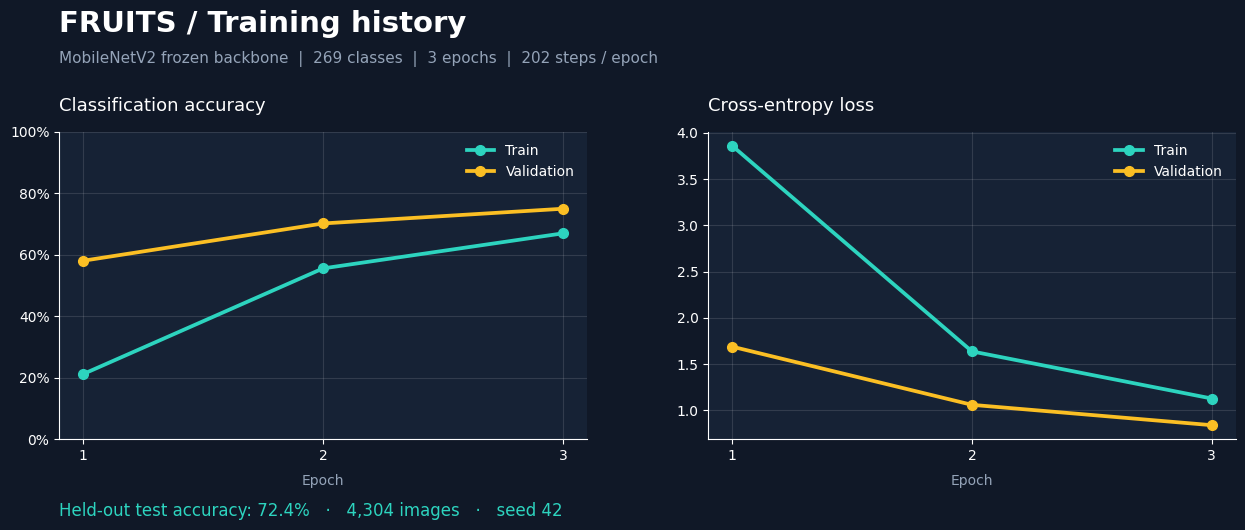

In [20]:
plt.style.use('dark_background')
from matplotlib.ticker import PercentFormatter
BG, PANEL, TEAL, GOLD = '#101827', '#162235', '#2dd4bf', '#fbbf24'
fig, axes = plt.subplots(1, 2, figsize=(13, 5.3), facecolor=BG)
for ax, key, title in zip(axes, ['accuracy', 'loss'], ['Classification accuracy', 'Cross-entropy loss']):
    ax.set_facecolor(PANEL)
    epochs = np.arange(1, len(history.history[key]) + 1)
    ax.plot(epochs, history.history[key], 'o-', color=TEAL, label='Train', linewidth=2.7, markersize=7)
    ax.plot(epochs, history.history['val_' + key], 'o-', color=GOLD, label='Validation', linewidth=2.7, markersize=7)
    ax.set_title(title, loc='left', fontsize=13, pad=15)
    ax.set_xlabel('Epoch', color='#94a3b8', labelpad=8)
    ax.set_xticks(epochs)
    ax.grid(alpha=0.12)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(frameon=False)
    if key == 'accuracy':
        ax.set_ylim(0, 1)
        ax.yaxis.set_major_formatter(PercentFormatter(1))
fig.suptitle('FRUITS / Training history', x=0.065, ha='left', fontsize=21, fontweight='bold', y=0.98)
fig.text(0.065, 0.88, f"MobileNetV2 frozen backbone  |  {NUM_CLASSES} classes  |  {len(history.history['loss'])} epochs  |  {fit_steps} steps / epoch", color='#94a3b8', fontsize=11)
fig.text(0.065, 0.025, f'Held-out test accuracy: {test_accuracy:.1%}   ·   {test_generator.samples:,} images   ·   seed {SEED}', color=TEAL, fontsize=12)
fig.subplots_adjust(top=0.75, bottom=0.17, left=0.065, right=0.97, wspace=0.23)
fig.savefig(ARTIFACT_DIR / 'training_history.png', dpi=160, facecolor=fig.get_facecolor())
plt.show()


## 9. Загрузка и предсказание
Порядок классов берётся из сохранённого JSON. Функция использует ту же предобработку, что и обучение.

In [21]:
model = tf.keras.models.load_model(ARTIFACT_DIR / 'fruits_mobilenet_v2.keras')
class_indices = json.loads((ARTIFACT_DIR / 'class_indices.json').read_text(encoding='utf-8'))
class_labels = {int(index): name for name, index in class_indices.items()}

def predict_fruit(img_path):
    img = image.load_img(img_path, target_size=IMAGE_SIZE, color_mode='rgb')
    img_array = preprocess_input(image.img_to_array(img))
    predictions = model.predict(np.expand_dims(img_array, axis=0), verbose=0)[0]
    index = int(np.argmax(predictions))
    return class_labels[index], float(predictions[index]), img

## 10. Примеры на отложенных изображениях
Случайные примеры из test-подвыборки (seed=42), без отбора по правильности. Зелёный заголовок — правильный класс; оранжевый — ошибка. Softmax-score не является гарантией правильного ответа.

135/135 ━━━━━━━━━━━━━━━━━━━━ 31s 218ms/step


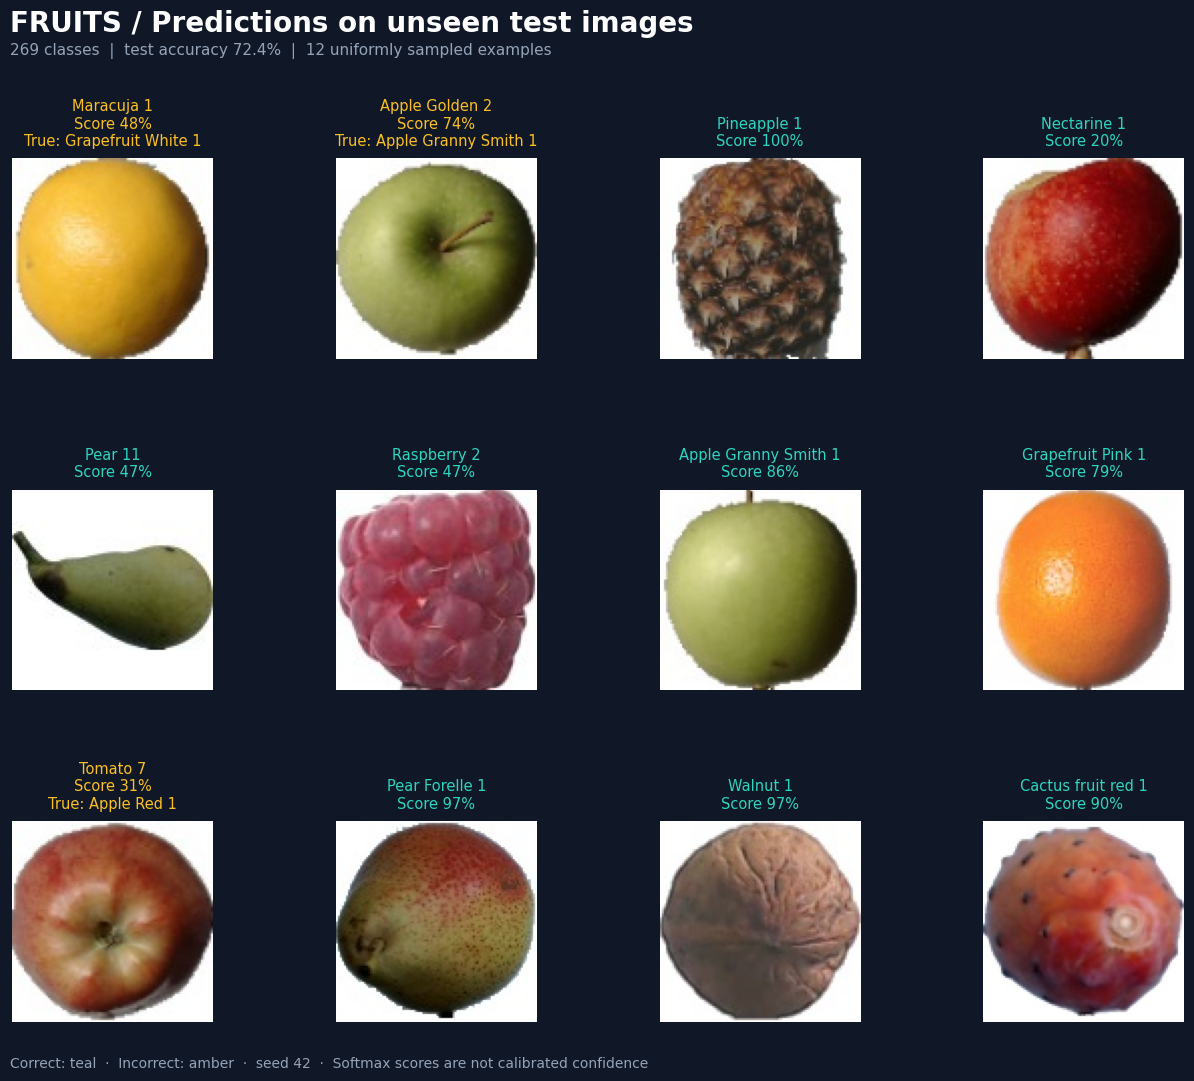

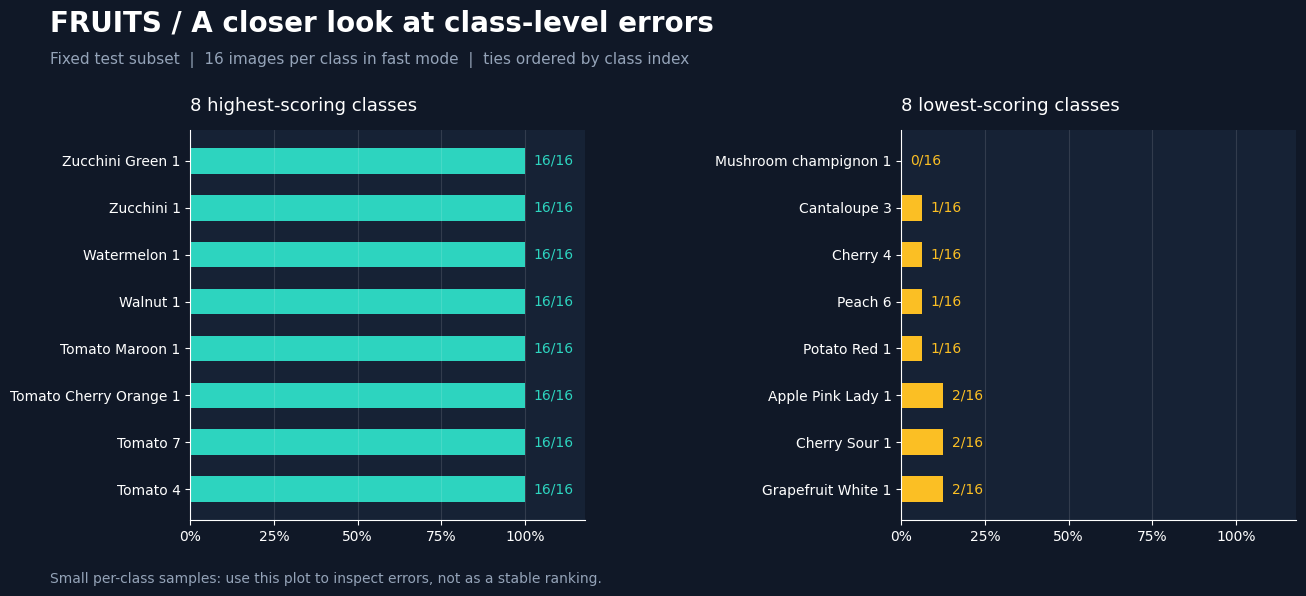

In [22]:
test_generator.reset()
probabilities = model.predict(test_generator, verbose=1)
y_true = np.asarray(test_generator.classes)
y_pred = probabilities.argmax(axis=1)
example_ids = np.random.default_rng(SEED).choice(len(y_true), size=min(12, len(y_true)), replace=False)
fig, axes = plt.subplots(3, 4, figsize=(13, 11), facecolor=BG)
for ax, index in zip(axes.flat, example_ids):
    img = image.load_img(test_generator.filepaths[index])
    true_label, pred_label = class_labels[int(y_true[index])], class_labels[int(y_pred[index])]
    correct = y_true[index] == y_pred[index]
    ax.imshow(img)
    title = textwrap.fill(pred_label, width=25) + f"\nScore {probabilities[index, y_pred[index]]:.0%}"
    if not correct:
        title += '\nTrue: ' + textwrap.fill(true_label, width=24)
    ax.set_title(title, color=TEAL if correct else GOLD, fontsize=10.5, pad=9)
    ax.axis('off')
fig.suptitle('FRUITS / Predictions on unseen test images', x=0.055, ha='left', fontsize=20, fontweight='bold', y=0.985)
fig.text(0.055, 0.944, f'{NUM_CLASSES} classes  |  test accuracy {test_accuracy:.1%}  |  12 uniformly sampled examples', color='#94a3b8', fontsize=11)
fig.text(0.055, 0.023, f'Correct: teal  ·  Incorrect: amber  ·  seed {SEED}  ·  Softmax scores are not calibrated confidence', color='#94a3b8', fontsize=10)
fig.subplots_adjust(top=0.85, bottom=0.065, left=0.045, right=0.97, hspace=0.65, wspace=0.4)
fig.savefig(ARTIFACT_DIR / 'predictions.png', dpi=150, facecolor=fig.get_facecolor())
plt.show()

class_accuracy = np.array([
    np.mean(y_pred[y_true == index] == index) for index in range(NUM_CLASSES)
])
order = np.argsort(class_accuracy, kind='stable')
fig, axes = plt.subplots(1, 2, figsize=(14, 6), facecolor=BG)
for ax, selected, title, color in [
    (axes[0], order[-8:][::-1], '8 highest-scoring classes', TEAL),
    (axes[1], order[:8], '8 lowest-scoring classes', GOLD),
]:
    ax.set_facecolor(PANEL)
    positions = np.arange(len(selected))
    values = class_accuracy[selected]
    ax.barh(positions, values, color=color, height=0.55)
    ax.set_yticks(positions, [textwrap.fill(class_labels[int(i)], 22) for i in selected], fontsize=10)
    ax.invert_yaxis()
    for row, index in enumerate(selected):
        count = int(np.sum(y_true == index))
        correct = int(np.sum((y_true == index) & (y_pred == index)))
        ax.text(values[row] + 0.025, row, f'{correct}/{count}', va='center', color=color, fontsize=10)
    ax.set_xlim(0, 1.18)
    ax.set_xticks([0, .25, .5, .75, 1])
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_title(title, loc='left', fontsize=13, pad=14)
    ax.grid(axis='x', alpha=0.12)
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('FRUITS / A closer look at class-level errors', x=0.06, ha='left', fontsize=20, fontweight='bold', y=0.98)
fig.text(0.06, 0.89, f'Fixed test subset  |  {FAST_TEST_PER_CLASS} images per class in fast mode  |  ties ordered by class index', color='#94a3b8', fontsize=11)
fig.text(0.06, 0.025, 'Small per-class samples: use this plot to inspect errors, not as a stable ranking.', color='#94a3b8', fontsize=10)
fig.subplots_adjust(top=0.78, bottom=0.13, left=0.16, right=0.95, wspace=0.8)
fig.savefig(ARTIFACT_DIR / 'class_accuracy.png', dpi=160, facecolor=fig.get_facecolor())
plt.show()
